<a href="https://colab.research.google.com/github/Divya4325/Cleaned-Banana-Classification-Detection/blob/main/03_Transfer_learning_comparison.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!unzip /content/drive/MyDrive/Clean_Banana_dataset.zip -d /content/Clean_Banana_dataset

Streaming output truncated to the last 5000 lines.
  inflating: /content/Clean_Banana_dataset/content/Clean_Banana_dataset/train/ripe/musa-acuminata-freshripe-46f5d22b-2653-11ec-a8ca-d8c4975e38aa_jpg.rf.f518e9357be5b406205cd9caa7d3e035.jpg  
  inflating: /content/Clean_Banana_dataset/content/Clean_Banana_dataset/train/ripe/musa-acuminata-ripe-9412bd5f-1d0a-11ec-9f9d-d8c4975e38aa_jpg.rf.30b533fd9321b09c6673a4c71e3bd6a1.jpg  
  inflating: /content/Clean_Banana_dataset/content/Clean_Banana_dataset/train/ripe/musa-acuminata-ripe-93a77c50-1d0a-11ec-a354-d8c4975e38aa_jpg.rf.17f2af3f90528538a97cb05eb8b11328.jpg  
  inflating: /content/Clean_Banana_dataset/content/Clean_Banana_dataset/train/ripe/musa-acuminata-ripe-6b6b4bc6-2653-11ec-b2ff-d8c4975e38aa_jpg.rf.a623a5134bb20073108f578d5769eefb.jpg  
  inflating: /content/Clean_Banana_dataset/content/Clean_Banana_dataset/train/ripe/musa-acuminata-freshripe-4cc9d76e-2653-11ec-8ae4-d8c4975e38aa_jpg.rf.e86c3e54c436a35ff36b9bbfe48acd60.jpg  
  inflati

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mobilenet_preprocess
from tensorflow.keras.applications.efficientnet import preprocess_input as efficienet_preprocess
from tensorflow.keras.applications.resnet import preprocess_input as resnet_preprocess

In [ ]:
#MobileNetV2
train_datagen_mobilenet = ImageDataGenerator(
    preprocessing_function = mobilenet_preprocess,
    rotation_range = 20,
    horizontal_flip = True
)

valid_datagen_mobilenet = ImageDataGenerator(preprocessing_function=mobilenet_preprocess)

test_datagen_mobilenet = ImageDataGenerator(preprocessing_function=mobilenet_preprocess)

# Paths
train_path = "/content/Clean_Banana_dataset/content/Clean_Banana_dataset/train"
valid_path = "/content/Clean_Banana_dataset/content/Clean_Banana_dataset/valid"
test_path  = "/content/Clean_Banana_dataset/content/Clean_Banana_dataset/test"

# Generators
train_gen_mobilenet = train_datagen_mobilenet.flow_from_directory(
    train_path,
    target_size=(224,224),
    batch_size=32,
    class_mode='categorical'
)

valid_gen_mobilenet = valid_datagen_mobilenet.flow_from_directory(
    valid_path,
    target_size=(224,224),
    batch_size=32,
    class_mode='categorical'
)

test_gen_mobilenet = test_datagen_mobilenet.flow_from_directory(
    test_path,
    target_size=(224,224),
    batch_size=32,
    class_mode='categorical',
    shuffle=False
)

num_classes = train_gen_mobilenet.num_classes

Found 8923 images belonging to 4 classes.
Found 1123 images belonging to 4 classes.
Found 562 images belonging to 4 classes.


In [ ]:
#EfficientNetB0
train_datagen_efficientnet = ImageDataGenerator(
    preprocessing_function = efficienet_preprocess,
    rotation_range = 20,
    horizontal_flip = True
)

valid_datagen_efficientnet = ImageDataGenerator(preprocessing_function=efficienet_preprocess)

test_datagen_efficientnet = ImageDataGenerator(preprocessing_function=efficienet_preprocess)

# Paths
train_path = "/content/Clean_Banana_dataset/content/Clean_Banana_dataset/train"
valid_path = "/content/Clean_Banana_dataset/content/Clean_Banana_dataset/valid"
test_path  = "/content/Clean_Banana_dataset/content/Clean_Banana_dataset/test"

# Generators
train_gen_efficientnet = train_datagen_efficientnet.flow_from_directory(
    train_path,
    target_size=(224,224),
    batch_size=32,
    class_mode='categorical'
)

valid_gen_efficientnet = valid_datagen_efficientnet.flow_from_directory(
    valid_path,
    target_size=(224,224),
    batch_size=32,
    class_mode='categorical'
)

test_gen_efficientnet = test_datagen_efficientnet.flow_from_directory(
    test_path,
    target_size=(224,224),
    batch_size=32,
    class_mode='categorical',
    shuffle=False
)
num_classes = train_gen_efficientnet.num_classes

Found 8923 images belonging to 4 classes.
Found 1123 images belonging to 4 classes.
Found 562 images belonging to 4 classes.


In [ ]:
#ResNet
train_datagen_resnet = ImageDataGenerator(
    preprocessing_function = resnet_preprocess,
    rotation_range = 20,
    horizontal_flip = True
)

valid_datagen_resnet = ImageDataGenerator(preprocessing_function=resnet_preprocess)

test_datagen_renest = ImageDataGenerator(preprocessing_function=resnet_preprocess)

# Paths
train_path = "/content/Clean_Banana_dataset/content/Clean_Banana_dataset/train"
valid_path = "/content/Clean_Banana_dataset/content/Clean_Banana_dataset/valid"
test_path  = "/content/Clean_Banana_dataset/content/Clean_Banana_dataset/test"

# Generators
train_gen_resnet = train_datagen_resnet.flow_from_directory(
    train_path,
    target_size=(224,224),
    batch_size=32,
    class_mode='categorical'
)

valid_gen_resnet = valid_datagen_resnet.flow_from_directory(
    valid_path,
    target_size=(224,224),
    batch_size=32,
    class_mode='categorical'
)

test_gen_resnet = test_datagen_renest.flow_from_directory(
    test_path,
    target_size=(224,224),
    batch_size=32,
    class_mode='categorical',
    shuffle=False
)
num_classes = train_gen_resnet.num_classes

Found 8923 images belonging to 4 classes.
Found 1123 images belonging to 4 classes.
Found 562 images belonging to 4 classes.


# MobileNetV2 Transfer Learning

In [ ]:
import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.models import Model
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, CSVLogger, ReduceLROnPlateau

In [ ]:
tf.keras.mixed_precision.set_global_policy('mixed_float16')
#Load Base MobileNetV2
base_model = MobileNetV2(
    input_shape=(224,224,3),
    include_top=False,
    weights='imagenet'
)
#Freeze base Layers initially
base_model.trainable= False

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
from numpy import dtypes
# Add Custom Classification Head
x = base_model.output
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dense(64, activation ='relu')(x)
x = tf.keras.layers.Dropout(0.4)(x)
predictions = tf.keras.layers.Dense(train_gen_mobilenet.num_classes, activation ='softmax',dtype='float32')(x)
model = Model(inputs= base_model.input, outputs=predictions)

In [ ]:
model.compile(
    optimizer ='adam',
    loss ='categorical_crossentropy',
    metrics = ['accuracy']
)

In [ ]:
#Callbacks:
callbacks = [
    EarlyStopping(monitor='val_loss',patience =3, restore_best_weights= True),
    ReduceLROnPlateau(monitor ='val_loss',factor =0.2, patience =2, min_lr=1e-6),
    CSVLogger("mobilenetv2_training_log.csv",append = True)
]

In [ ]:
# Train the model
history =model.fit(
    train_gen_mobilenet,
    validation_data= valid_gen_mobilenet,
    epochs =20,
    callbacks=callbacks
)

Epoch 1/20
279/279 ━━━━━━━━━━━━━━━━━━━━ 228s 667ms/step - accuracy: 0.8725 - loss: 0.3561 - val_accuracy: 0.9038 - val_loss: 0.2743 - learning_rate: 0.0010
Epoch 2/20
279/279 ━━━━━━━━━━━━━━━━━━━━ 123s 441ms/step - accuracy: 0.9294 - loss: 0.1976 - val_accuracy: 0.9288 - val_loss: 0.2087 - learning_rate: 0.0010
Epoch 3/20
279/279 ━━━━━━━━━━━━━━━━━━━━ 121s 433ms/step - accuracy: 0.9427 - loss: 0.1597 - val_accuracy: 0.8842 - val_loss: 0.3031 - learning_rate: 0.0010
Epoch 4/20
279/279 ━━━━━━━━━━━━━━━━━━━━ 122s 437ms/step - accuracy: 0.9507 - loss: 0.1419 - val_accuracy: 0.8896 - val_loss: 0.2995 - learning_rate: 0.0010
Epoch 5/20
279/279 ━━━━━━━━━━━━━━━━━━━━ 121s 432ms/step - accuracy: 0.9655 - loss: 0.1099 - val_accuracy: 0.9101 - val_loss: 0.2431 - learning_rate: 2.0000e-04


In [ ]:
from google.colab import files
files.download("/content/drive/MyDrive/mobilenetv2_banana_model.h5")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
model.save('/content/drive/MyDrive/mobilenetv2_banana_model.h5')

In [ ]:
from google.colab import files  #Don't run this again becoz model saved locally
files.download("mobilenetv2_banana_model.h5")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files  #Don't run this again becoz model saved locally
files.download("mobilenetv2_training_log.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

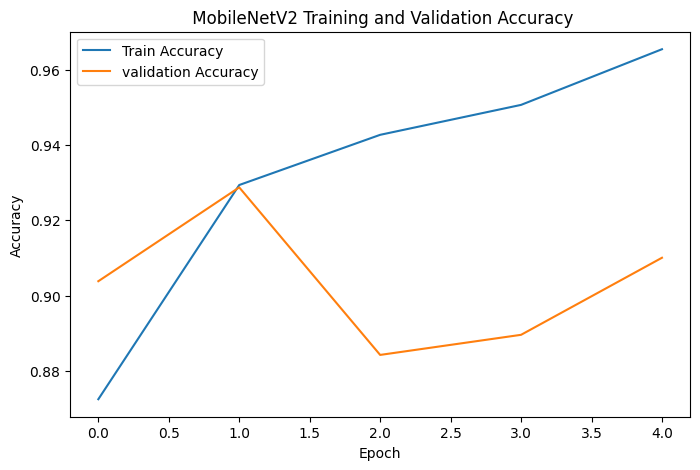

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8,5))
plt.plot(history.history['accuracy'],label='Train Accuracy')
plt.plot(history.history['val_accuracy'],label='validation Accuracy')
plt.title(' MobileNetV2 Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.savefig("/content/drive/MyDrive/mobilenetv2_accuracy_graph.png",dpi=300,bbox_inches="tight")
plt.show()

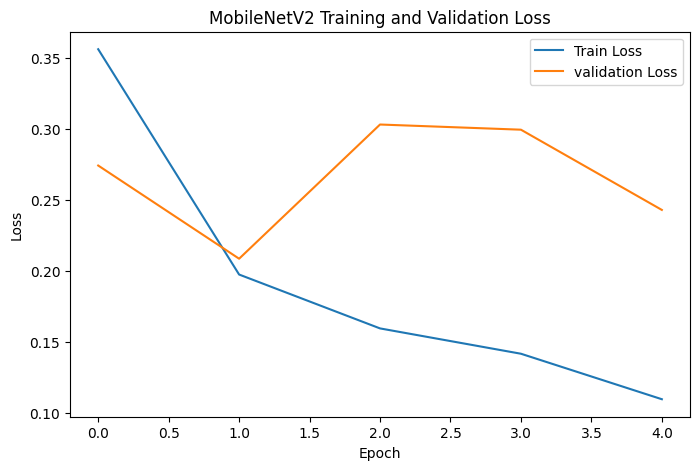

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8,5))
plt.plot(history.history['loss'],label='Train Loss')
plt.plot(history.history['val_loss'],label='validation Loss')
plt.title('MobileNetV2 Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.savefig("/content/drive/MyDrive/mobilenetv2_loss_graph.png",dpi=300,bbox_inches="tight")
plt.show()

## **EfficientNetB0**

In [ ]:
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.models import Model
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, CSVLogger, ModelCheckpoint

In [ ]:
#Base Model
base_model = EfficientNetB0(
    weights='imagenet',
    include_top =False,
    input_shape =(224,224,3)
)
#Custom Classification Head
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(64,activation ='relu')(x)
x = Dropout(0.4)(x)
predictions = Dense(num_classes,activation = 'softmax')(x)
model = Model(inputs = base_model.input, outputs= predictions)

In [ ]:
#Compile
model.compile(
    optimizer =Adam(learning_rate = 0.001),
    loss ='categorical_crossentropy',
    metrics =['accuracy'])

In [ ]:
#Callbacks
callbacks = [
    EarlyStopping(monitor='val_loss',patience = 5, restore_best_weights = True),
    ReduceLROnPlateau(monitor ='val_loss',factor = 0.2, patience =3, min_lr=1e-6, verbose= 1),
    CSVLogger("efficientb0_training_log.csv",append = True)
]

In [ ]:
# Train the model
history =model.fit(
    train_gen_efficientnet,
    validation_data= valid_gen_efficientnet,
    epochs =15,
    callbacks=callbacks
)

Epoch 1/15
279/279 ━━━━━━━━━━━━━━━━━━━━ 392s 925ms/step - accuracy: 0.9311 - loss: 0.2297 - val_accuracy: 0.8682 - val_loss: 0.5930 - learning_rate: 0.0010
Epoch 2/15
279/279 ━━━━━━━━━━━━━━━━━━━━ 129s 461ms/step - accuracy: 0.9677 - loss: 0.1067 - val_accuracy: 0.9190 - val_loss: 0.4343 - learning_rate: 0.0010
Epoch 3/15
279/279 ━━━━━━━━━━━━━━━━━━━━ 134s 481ms/step - accuracy: 0.9725 - loss: 0.0898 - val_accuracy: 0.9074 - val_loss: 0.3730 - learning_rate: 0.0010
Epoch 4/15
279/279 ━━━━━━━━━━━━━━━━━━━━ 134s 480ms/step - accuracy: 0.9778 - loss: 0.0730 - val_accuracy: 0.9216 - val_loss: 0.2979 - learning_rate: 0.0010
Epoch 5/15
279/279 ━━━━━━━━━━━━━━━━━━━━ 132s 470ms/step - accuracy: 0.9781 - loss: 0.0814 - val_accuracy: 0.8531 - val_loss: 0.9091 - learning_rate: 0.0010
Epoch 6/15
279/279 ━━━━━━━━━━━━━━━━━━━━ 130s 467ms/step - accuracy: 0.9821 - loss: 0.0573 - val_accuracy: 0.9457 - val_loss: 0.3026 - learning_rate: 0.0010
Epoch 7/15
279/279 ━━━━━━━━━━━━━━━━━━━━ 0s 461ms/step - accuracy

In [ ]:
model.save('/content/drive/MyDrive/efficientnetb0_banana_model.h5')

In [ ]:
from google.colab import files
files.download("/content/drive/MyDrive/efficientnetb0_banana_model.h5")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files  #Don't run this again becoz model saved locally
files.download("efficientnetb0_banana_model.h5")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files  #Don't run this again becoz model saved locally
files.download("efficientb0_training_log.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

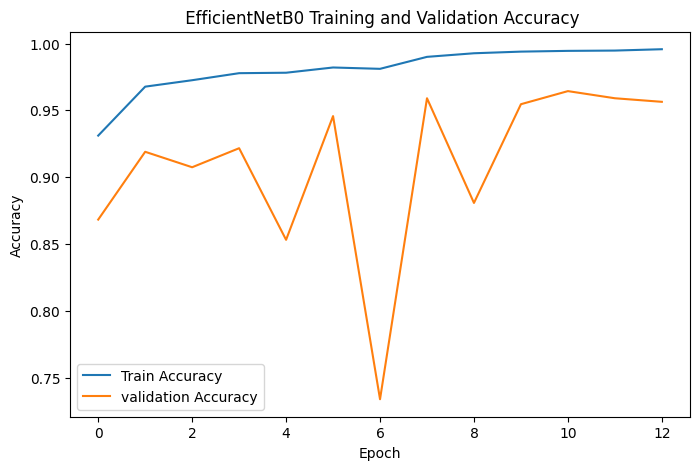

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8,5))
plt.plot(history.history['accuracy'],label='Train Accuracy')
plt.plot(history.history['val_accuracy'],label='validation Accuracy')
plt.title(' EfficientNetB0 Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.savefig("/content/drive/MyDrive/efficientnetb0_accuracy_graph.png",dpi=300,bbox_inches="tight")
plt.show()

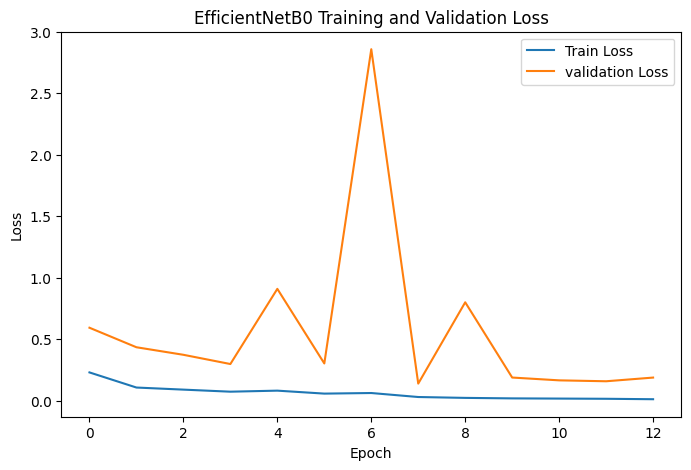

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8,5))
plt.plot(history.history['loss'],label='Train Loss')
plt.plot(history.history['val_loss'],label='validation Loss')
plt.title('EfficientNetB0 Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.savefig("/content/drive/MyDrive/efficientnetb0_loss_graph.png",dpi=300,bbox_inches="tight")
plt.show()

# **RESNET50**

In [ ]:
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.models import Model
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, CSVLogger

In [ ]:
#Base Model
base_model =ResNet50(
    weights='imagenet',
    include_top =False,
    input_shape =(224,224,3)
)
#Custom Classification Head
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(64,activation ='relu', kernel_regularizer= tf.keras.regularizers.l2(0.001))(x)
x = Dropout(0.5)(x)
predictions = Dense(num_classes,activation = 'softmax',dtype='float32')(x)
model = tf.keras.Model(inputs = base_model.input, outputs= predictions)

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [ ]:
#Compile
model.compile(
    optimizer =Adam(learning_rate = 1e-4),
    loss ='categorical_crossentropy',
    metrics =['accuracy'])

In [ ]:
#Callbacks
callbacks = [
    EarlyStopping(monitor='val_loss',patience = 5, restore_best_weights = True),
    ReduceLROnPlateau(monitor ='val_loss',factor = 0.2, patience =2, min_lr=1e-6),
    CSVLogger("resnet50_training_log.csv",append = True)
]

In [ ]:
history =model.fit(
    train_gen_resnet,
    validation_data= valid_gen_resnet,
    epochs =20,
    callbacks=callbacks
)

Epoch 1/20
279/279 ━━━━━━━━━━━━━━━━━━━━ 289s 712ms/step - accuracy: 0.9250 - loss: 0.3515 - val_accuracy: 0.8807 - val_loss: 0.5780 - learning_rate: 1.0000e-04
Epoch 2/20
279/279 ━━━━━━━━━━━━━━━━━━━━ 134s 480ms/step - accuracy: 0.9704 - loss: 0.2092 - val_accuracy: 0.8664 - val_loss: 0.7673 - learning_rate: 1.0000e-04
Epoch 3/20
279/279 ━━━━━━━━━━━━━━━━━━━━ 132s 473ms/step - accuracy: 0.9801 - loss: 0.1807 - val_accuracy: 0.8842 - val_loss: 0.6251 - learning_rate: 1.0000e-04
Epoch 4/20
279/279 ━━━━━━━━━━━━━━━━━━━━ 136s 487ms/step - accuracy: 0.9879 - loss: 0.1497 - val_accuracy: 0.9083 - val_loss: 0.6060 - learning_rate: 2.0000e-05
Epoch 5/20
279/279 ━━━━━━━━━━━━━━━━━━━━ 135s 483ms/step - accuracy: 0.9920 - loss: 0.1328 - val_accuracy: 0.9038 - val_loss: 0.6676 - learning_rate: 2.0000e-05
Epoch 6/20
279/279 ━━━━━━━━━━━━━━━━━━━━ 136s 487ms/step - accuracy: 0.9920 - loss: 0.1300 - val_accuracy: 0.9118 - val_loss: 0.5978 - learning_rate: 4.0000e-06


In [ ]:
model.save('/content/drive/MyDrive/resnet50_banana_model.h5')

In [ ]:
from google.colab import files  #Don't run this again becoz model saved locally
files.download("resnet50_banana_model.h5")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files  #Don't run this again becoz model saved locally
files.download("resnet50_training_log.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

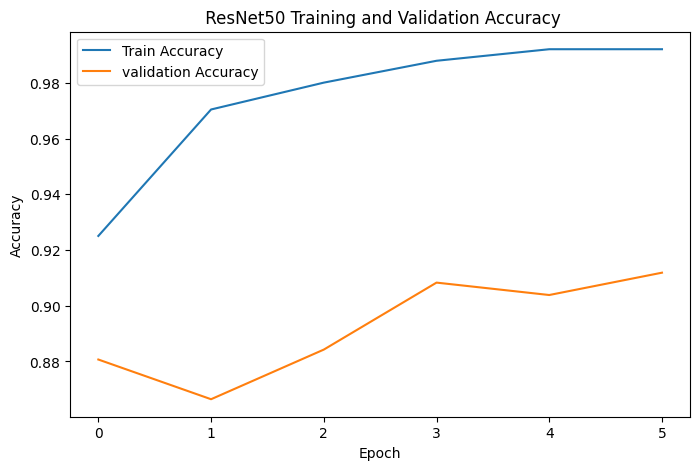

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8,5))
plt.plot(history.history['accuracy'],label='Train Accuracy')
plt.plot(history.history['val_accuracy'],label='validation Accuracy')
plt.title(' ResNet50 Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.savefig("/content/drive/MyDrive/resnet50_accuracy_graph.png",dpi=300,bbox_inches="tight")
plt.show()

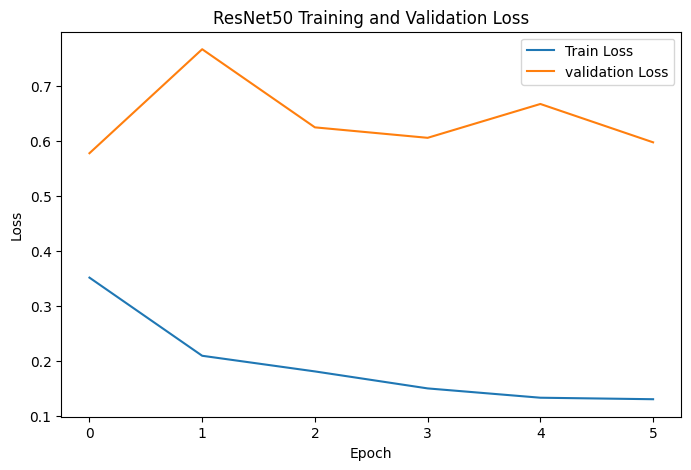

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8,5))
plt.plot(history.history['loss'],label='Train Loss')
plt.plot(history.history['val_loss'],label='validation Loss')
plt.title('ResNet50 Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.savefig("/content/drive/MyDrive/resnet50_loss_graph.png",dpi=300,bbox_inches="tight")
plt.show()

# **YOLOv8 Classification**

In [ ]:
pip install ultralytics

In [ ]:
from ultralytics import YOLO

In [ ]:
model = YOLO("yolov8n-cls.pt")

In [ ]:
# Train the Model
results = model.train(
    data = "/content/Clean_Banana_dataset/content/Clean_Banana_dataset",
    epochs = 50,
    imgsz = 224,
    batch =32,
    patience = 10
)

Ultralytics 8.4.89 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Clean_Banana_dataset/content/Clean_Banana_dataset, degrees=0.0, deterministic=True, device=, dfl=1.5, dis=6.0, distill_model=None, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=224, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n-cls.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-3, nbs=64, nms=False, opset=None, optimize=False, optimizer=au

In [ ]:
#Validate
metrics = model.val()

Ultralytics 8.4.89 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8n-cls summary (fused): 30 layers, 1,440,004 parameters, 0 gradients, 3.3 GFLOPs
train: /content/Clean_Banana_dataset/content/Clean_Banana_dataset/train... found 8923 images in 4 classes ✅ 
val: /content/Clean_Banana_dataset/content/Clean_Banana_dataset/valid... found 1123 images in 4 classes ✅ 
test: /content/Clean_Banana_dataset/content/Clean_Banana_dataset/test... found 562 images in 4 classes ✅ 
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1342.4±535.8 MB/s, size: 45.7 KB)
val: Scanning /content/Clean_Banana_dataset/content/Clean_Banana_dataset/valid... 1123 images, 0 corrupt: 100% ━━━━━━━━━━━━ 1123/1123 224.3Mit/s 0.0s
               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 71/71 12.4it/s 5.7s
                   all       0.98          1
Speed: 0.1ms preprocess, 0.8ms inference, 0.0ms loss, 0.0ms postprocess per image
Results saved to /content/runs/classify/val


In [ ]:
from google.colab import files
files.download('/content/runs/classify/train-3/weights/best.pt')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
model = YOLO('/content/runs/classify/train-3/weights/best.pt')
results = model.predict(
    source = '/content/Clean_Banana_dataset/content/Clean_Banana_dataset/test/ripe/musa-acuminata-freshripe-44b50885-2653-11ec-8617-d8c4975e38aa_jpg.rf.064f5ad40995480c20b912357ecd9e2b.jpg',
    imgsz = 224,
    save = True
)


image 1/1 /content/Clean_Banana_dataset/content/Clean_Banana_dataset/test/ripe/musa-acuminata-freshripe-44b50885-2653-11ec-8617-d8c4975e38aa_jpg.rf.064f5ad40995480c20b912357ecd9e2b.jpg: 224x224 ripe 0.97, overripe 0.03, unripe 0.00, rotten 0.00, 3.7ms
Speed: 4.4ms preprocess, 3.7ms inference, 0.1ms postprocess per image at shape (1, 3, 224, 224)
Results saved to /content/runs/classify/predict


**Prediction**

In [ ]:
print("Predicted Class:",results[0].names[results[0].probs.top1])
print("Confidence:",results[0].probs.top1conf.item())

Predicted Class: ripe
Confidence: 0.9658011794090271


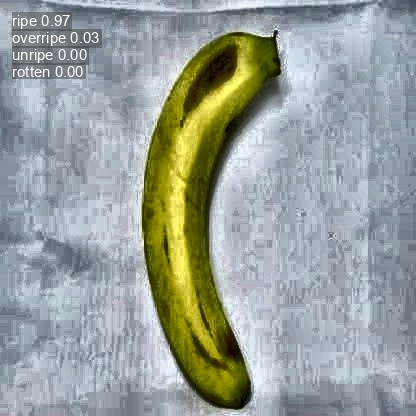

In [ ]:
from IPython.display import Image,display
display(Image(filename='/content/runs/classify/predict/musa-acuminata-freshripe-44b50885-2653-11ec-8617-d8c4975e38aa_jpg.rf.064f5ad40995480c20b912357ecd9e2b.jpg'))